# EDA: Hyperallergic Pages and Organizer Pages

The Organizer Pages are the pages we obtained from the links in the opportunities/pages we scrapped from the Hyperallergic website.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re

### Load and Join



In [2]:
# listings = pd.read_json("data/hyperallergic.jsonl", lines=True) # to tell pandas to read the file line by line
## this won't work as it does on local computer, first we need to connect to my google drive

In [3]:
# !ls -F data/

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

# Now we can read a file, for example:
# file_path = '/content/drive/MyDrive/your_file_name.csv'
# df = pd.read_csv(file_path)
# print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [17]:
# file_path = '/content/drive/MyDrive/DLArtManager/data/hyperallergic.jsonl'
# listings = pd.read_json(file_path, lines=True)

file_path = '../data/raw/hyperallergic.jsonl'
listings = pd.read_json(file_path, lines=True)

np.random.seed(1)
display(listings.sample(10))

,title,description,deadline,fees,website,raw_text,type,source,source_url,published_at,scraped_at
363,Collar Works – Elizabeth Murray Artist Residency,"Held on a 77-acre farm in Granville, New York,...","September 1, 2024",NaN,https://www.collarworks.org/emar,Collar Works – Elizabeth Murray Artist Residen...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-august...,2024-08-01 19:00:00+00:00,2026-10-07 05:46:54+00:00
62,Banff Centre for Arts and Creativity – Visual ...,Develop your work in a Visual Arts residency a...,"May 6, 2026 (Visual Arts Thematic – On Other A...",The application fee is $65 ($35 for applicants...,https://www.banffcentre.ca/visual-arts,Banff Centre for Arts and Creativity – Visual ...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-april-...,2026-04-02 12:00:28+00:00,2026-10-07 05:46:54+00:00
322,Visual AIDS – Postcards From the Edge,"Donate an original, postcard-sized artwork to ...","November 22, 2024",NaN,https://www.postcards.visualaids.org/,Visual AIDS – Postcards From the Edge\nDonate ...,Open Call,hyperallergic,https://hyperallergic.com/opportunities-novemb...,2024-11-01 16:00:00+00:00,2026-10-07 05:46:54+00:00
92,Textile Arts Center – Artist in Residence Cycl...,Providing an opportunity to explore the textil...,"March 6, 2026","Tuition is $11,000, the application fee is $35.",https://textileartscenter.com/artist-opportuni...,Textile Arts Center – Artist in Residence Cycl...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-in-feb...,2026-02-02 21:36:57+00:00,2026-10-07 05:46:54+00:00
146,at Louis Place – Artist Publishing Cohort,This new initiative offers personalized suppor...,"October 24, 2025",NaN,https://atlouisplace.com/cohort,at Louis Place – Artist Publishing Cohort\nThi...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-octobe...,2025-10-01 18:00:00+00:00,2026-10-07 05:46:54+00:00
338,Open Source – 2026 Exhibition Open Call,Applications are sought from artists worldwide...,"November 3, 2024",Selected artists will receive fees based on th...,https://open-source-gallery.org/open-call-for-...,Open Source – 2026 Exhibition Open Call\nAppli...,Open Call,hyperallergic,https://hyperallergic.com/opportunities-octobe...,2024-10-01 20:36:05+00:00,2026-10-07 05:46:54+00:00
242,Pratt Institute – Climate Studio Residency,"Artists, educators, and community organizers w...","April 15, 2025",NaN,https://www.pratt.edu/liberal-arts-and-science...,Pratt Institute – Climate Studio Residency\nAr...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-april-...,2025-04-02 16:30:00+00:00,2026-10-07 05:46:54+00:00
271,Onassis AiR Open Call 2025/26 – Residencies an...,Participants in the Onassis AiR residency prog...,"March 7, 2025 (12am EST/12pm UTC+2)",Participants in the Onassis AiR residency prog...,https://www.onassis.org/open-calls/onassis-air...,Featured\nOnassis AiR Open Call 2025/26 – Resi...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-februa...,2025-02-03 18:55:54+00:00,2026-10-07 05:46:54+00:00
29,Two Artist Fellowships - Hodder & PAF — Prince...,"Princeton Arts Fellowships - 2 years, teaching...","Sept. 8, 2026",NaN,http://arts.princeton.edu/fellowships,Two Artist Fellowships - Hodder & PAF — Prince...,Residency/Fellowship,hyperallergic,https://hyperallergic.com/opportunities-in-aug...,2026-08-03 15:00:27+00:00,2026-10-07 05:46:54+00:00
172,Foundwork – 2025 Foundwork Artist Prize,"The honoree receives a $10,000 grant and studi...","September 26, 2025 (5pm PT)",NaN,https://foundwork.art/artist-prize,\nFeatured\nFoundwork – 2025 Foundwork Artist ...,Grant,hyperallergic,https://hyperallergic.com/opportunities-septem...,2025-09-02 18:00:00+00:00,2026-10-07 05:46:54+00:00


It is the text between the title and the "Deadline:" label. For ArtFields, that is "Southern artists: compete for $100K+ in prizes ... Fee: $25".

In [18]:
listings.description[1]

'Manhattan-based individual artists, collectives, and non-profit organizations working across all artistic disciplines, backgrounds and neighborhoods are invited to apply for project and/or unrestricted grant support!'

In [19]:
listings.shape

(407, 11)

We have about 400 opportunities, we need to find duplicates in them.

In [8]:
listings.info()

<class 'pandas.DataFrame'>
RangeIndex: 407 entries, 0 to 406
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   title         407 non-null    str                
 1   description   407 non-null    str                
 2   deadline      400 non-null    str                
 3   fees          94 non-null     str                
 4   website       407 non-null    str                
 5   raw_text      407 non-null    str                
 6   type          407 non-null    str                
 7   source        407 non-null    str                
 8   source_url    407 non-null    str                
 9   published_at  407 non-null    datetime64[us, UTC]
 10  scraped_at    407 non-null    datetime64[us, UTC]
dtypes: datetime64[us, UTC](2), str(9)
memory usage: 356.1 KB


In [9]:
listings.isnull().sum()

title             0
description       0
deadline          7
fees            313
website           0
raw_text          0
type              0
source            0
source_url        0
published_at      0
scraped_at        0
dtype: int64

- fees has a lot of missing values - are these missing fees values in the possting or were we just not able to parse them?
- we do need all the deadlines so need to investigate these missing 7 deadline values
- the datatypes of all the features look okay for now; even though fees and deadline are in their correct datatypes, we probably don't need them to be to suggest it to the artist user

In [20]:
file_path = '../data/raw/opportunity_pages.jsonl'
pages = pd.read_json(file_path, lines=True)

np.random.seed(1)
display(pages.sample(10))

,source_url,raw_text,published_at,scraped_at
67,https://www.dagfoundation.org/the-dag-prize,top of page\n\nSkip to Main Content\n\nMenu\n\...,NaN,2026-10-07 06:05:12+00:00
250,https://www.redlineart.org/insite-fund,Apply for the INSITE Fund Colorado Artist Gran...,NaN,2026-10-07 06:29:42+00:00
230,https://centerforbookarts.org/artists-in-resid...,[Skip to content](https://centerforbookarts.or...,NaN,2026-10-07 06:27:37+00:00
161,https://artportkingston.org/new-page-56,ArtPort Kingston\n\n[![ArtPort Kingston](https...,NaN,2026-10-07 06:19:09+00:00
91,https://www.artistsandmothers.org/grant,#### Grant Guidelines\n\nArtists & Mothers is ...,NaN,2026-10-07 06:07:38+00:00
224,https://tyler.temple.edu/sites/tyler/files/Edg...,## Position Announcement Tyler School of Art a...,NaN,2026-10-07 06:26:53+00:00
58,https://franklinfurnace.org/grants-and-funding...,[Skip to content](https://franklinfurnace.org/...,NaN,2026-10-07 06:04:16+00:00
234,https://www.radcliffe.harvard.edu/radcliffe-fe...,[Skip to main content](https://www.radcliffe.h...,NaN,2026-10-07 06:28:02+00:00
180,https://www.galleryovissi.com/ovissi-foundation,We couldn't find the page you were looking for...,NaN,2026-10-07 06:22:32+00:00
4,https://apexart.org/opencalls.php,## OPEN CALLS\n\napexart's Open Calls are oppo...,NaN,2026-10-07 05:54:49+00:00


In [22]:
print(pages.shape)
pages.info()

(251, 4)
<class 'pandas.DataFrame'>
RangeIndex: 251 entries, 0 to 250
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   source_url    251 non-null    str                
 1   raw_text      251 non-null    str                
 2   published_at  15 non-null     str                
 3   scraped_at    251 non-null    datetime64[us, UTC]
dtypes: datetime64[us, UTC](1), str(3)
memory usage: 2.4 MB


In [13]:
# from scrapers.hyperallergic.common import url_key # this is not gonna work as the module is not in the path, we need to add it to the path first

In [ ]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":   # a notebook usually starts in its own folder
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "scrapers")) # went into scrapers folder to import common.py, so that we can use url_key function

from common import url_key # url_key is a function that takes a url and returns a unique key for that url-useful for deduplication (also clean urls - removing their trailing slashes, query parameters, etc.)


In [33]:
pd.set_option('display.max_colwidth', None)
pages['raw_text'].sample(5)

136                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     

Some issues in the text that we should be aware of:

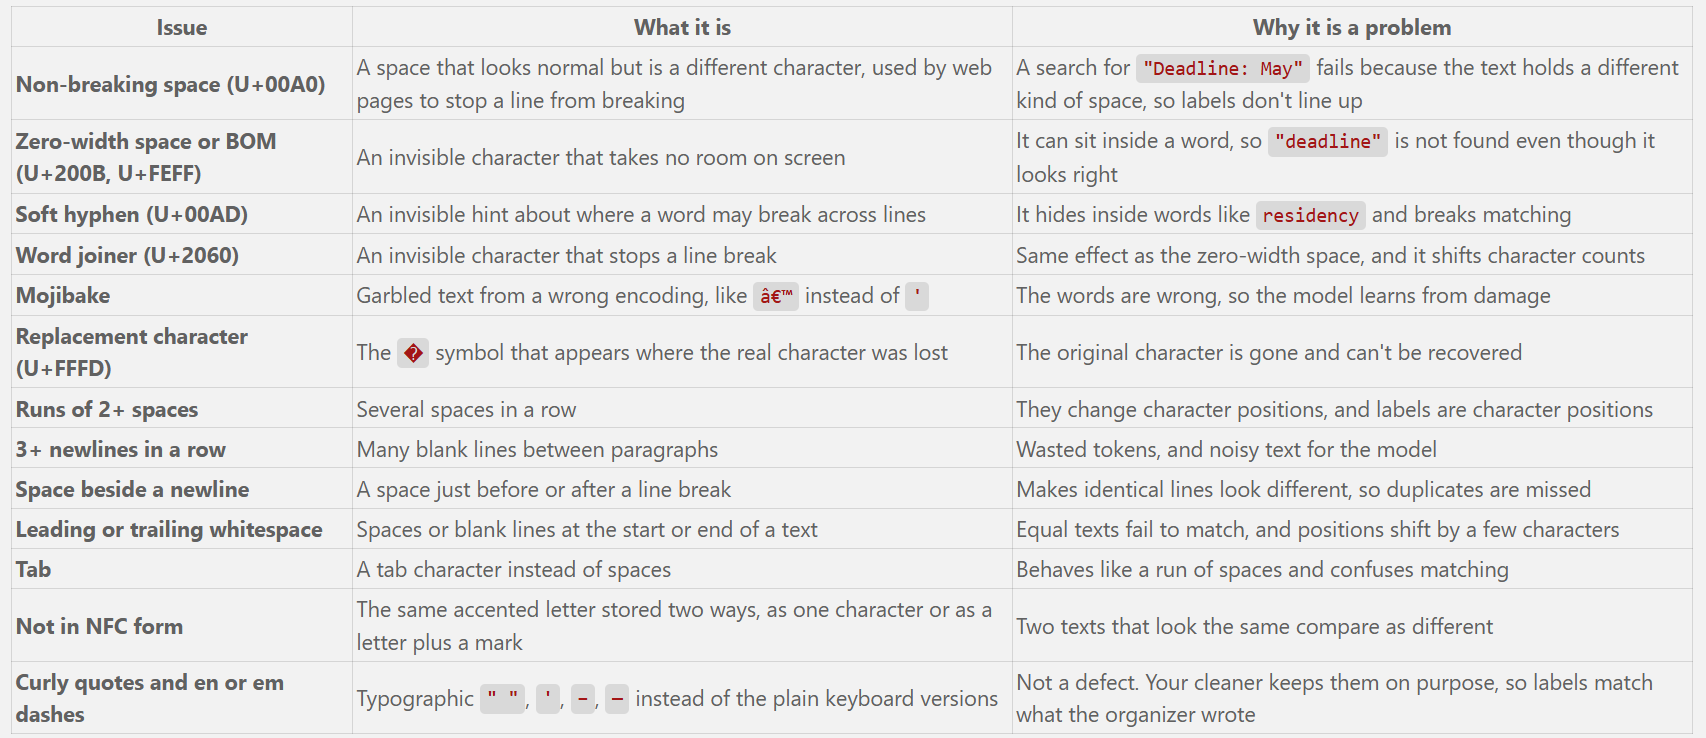

The main reason all of this matters: labels are character positions (start and end), and a model is trained on exactly the text those positions refer to. Anything that adds, hides, or changes characters after labeling shifts those positions. That is why your cleaner's docstring says to run it once, before labeling.

In [ ]:
import re, unicodedata, collections

checks = {
    "non-breaking space": lambda t: "\u00a0" in t,
    "zero-width / BOM":   lambda t: re.search("[\u200b\u200c\u200d\ufeff]", t) is not None,
    "mojibake":           lambda t: re.search("Ã.|â€|Â|\ufffd", t) is not None,
    "2+ spaces":          lambda t: "  " in t,
    "3+ newlines":        lambda t: "\n\n\n" in t,
    "edge whitespace":    lambda t: t != t.strip(),
}
for name, fn in checks.items():
    print(name, sum(fn(t) for t in pages["raw_text"]), "of", len(pages))

# every unusual character, with its name
c = collections.Counter(ch for t in pages["raw_text"] for ch in t
                        if ord(ch) > 127 and unicodedata.category(ch) in ("Zs", "Cf", "Cc"))
for ch, n in c.most_common(10):
    print(f"U+{ord(ch):04X}", unicodedata.name(ch, "?"), n)



non-breaking space 132 of 251
zero-width / BOM 17 of 251
mojibake 0 of 251
2+ spaces 76 of 251
3+ newlines 102 of 251
edge whitespace 2 of 251
U+00A0 NO-BREAK SPACE 2081
U+200B ZERO WIDTH SPACE 135
U+00AD SOFT HYPHEN 59
U+2060 WORD JOINER 43
U+202F NARROW NO-BREAK SPACE 28
U+200D ZERO WIDTH JOINER 26
U+2009 THIN SPACE 26
U+200E LEFT-TO-RIGHT MARK 8
U+FEFF ZERO WIDTH NO-BREAK SPACE 3
U+200A HAIR SPACE 1


1. At first let's deal with urls in the listings to become unique, we will use url_key function to do that, and then we will check if there are any duplicates in the listings based on the url_key 

2. We want that our model should train on one set of listings, as in the listings coming from one set of organizers and then test it on another. The test is meant to show how it does on listings it has never seen.

Organizers repeat themselves, (for ex: apexart appears 7 times in the data,) usually with almost the same wording and layout. If some apexart listings are in the training set and others in the test set, the model has already seen apexart's style. It scores well on the test by recognizing the organizer, not by understanding the text. 

This could lead to leakage, and makes the score look better than it really is. So we'll create a function 'domain' in which we group listings by domain(url) and send each group entirely to train or entirely to test - a group split. A model that does well on it has to handle organizers it has never seen, which is what it will meet in real use.



Example: domain takes a link such as https://www.apexart.org/opencalls.php and returns the site, apexart.org, without the www.. That site name stands for the organizer.


In [ ]:

from urllib.parse import urlparse
def domain(url):
    """The site of a link, without "www.". 
    Used to keep an organizer out of both train and test."""
    host = urlparse(url or "").netloc.lower()
    return host[4:] if host.startswith("www.") else host


listings["key"] = listings["website"].map(url_key)
pages["key"] = pages["source_url"].map(url_key)
listings["domain"] = listings["website"].map(domain)


Next, 
1. we also want to extract the month from the source_url, so that we can use it for later analysis, for example, to see if there is any seasonality in the data. We can do this by using the month_from_source_url function from the preprocess.clean module.

2. Very important for us to know 'why an organizer page is not usable text', or 'None' if it looks fine.

    "empty" is almost no text. "not_found" is an error page (the start of the
    text says the page is missing). "no_signal" is a page with no words a
    listing would use, such as a login wall or a cookie banner.
  


In [47]:
# extract month from source_url using the month_from_source_url function

MONTHS = {m: i for i, m in enumerate(
    ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], start=1)}

def month_from_source_url(url):
    """The month of a Hyperallergic post, such as "2025-04", from its address."""
    m = re.search(r"opportunities-(?:in-)?([a-z]+)-(\d{4})", url or "")
    if not m or m[1][:3] not in MONTHS:
        return None
    return f"{m[2]}-{MONTHS[m[1][:3]]:02d}"

# what the problem is with the page, using the page_problem function
def page_problem(text):
    """Say why an organizer page is not usable text, or None if it looks fine.

    "empty" is almost no text. "not_found" is an error page (the start of the
    text says the page is missing). "no_signal" is a page with no words a
    listing would use, such as a login wall or a cookie banner.
    """
    text = normalize_text(text)
    if len(text) < 200:
        return "empty"
    if _NOT_FOUND.search(text[:400]):
        return "not_found"
    if not _OPPORTUNITY_WORDS.search(text):
        return "no_signal"
    return None

import ftfy

_NOT_FOUND = re.compile(
    r"page not found|(?:couldn.t|can.t|could not) find (?:the|that) page|no longer (?:available|exists)|\b404\b", re.I
)
_OPPORTUNITY_WORDS = re.compile(
    r"\b(deadline|appl(?:y|ying|ication)|eligib|grant|residenc|fellowship|open call|submission|artist)", re.I
)

def page_problem(text):
    """Say why an organizer page is not usable text, or None if it looks fine.

    "empty" is almost no text. "not_found" is an error page (the start of the
    text says the page is missing). "no_signal" is a page with no words a
    listing would use, such as a login wall or a cookie banner.
    """
    text = normalize_text(text)
    if len(text) < 200:
        return "empty"
    if _NOT_FOUND.search(text[:400]):
        return "not_found"
    if not _OPPORTUNITY_WORDS.search(text):
        return "no_signal"
    return None

def normalize_text(text):
    """Make whitespace and invisible characters consistent.

    Fixes broken encodings, turns non-breaking spaces into plain spaces, drops
    zero-width characters, and collapses runs of spaces and blank lines. Curly
    quotes and en dashes are kept, because labels will be made on this text
    and should match what the organizer wrote. Run this once, before labeling:
    character positions change if it is run afterwards.
    """
    if not isinstance(text, str):
        return ""
    text = ftfy.fix_text(text)
    text = unicodedata.normalize("NFC", text)
    text = text.replace(" ", " ")
    text = re.sub(r"[​‌‍﻿]", "", text)
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r" ?\n ?", "\n", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

    
listings["month"] = listings["source_url"].map(month_from_source_url)
pages["problem"] = pages["raw_text"].map(page_problem)

print(pages["problem"].value_counts(dropna=False))

problem
NaN          226
not_found     14
no_signal      7
empty          4
Name: count, dtype: int64


25 of the 251 fetched pages are not usable (226 are): 14 are "page not found", 7 have no listing words (login walls, banners), 4 are nearly empty.

In [40]:
## now let's merge the listings and pages dataframes on the key column, using an inner join, 
# and keep only the columns we need: key, domain, month, raw_text, problem

df = listings.merge(pages[["key", "raw_text", "problem"]].rename(columns={"raw_text": "page_text"}),
                    on="key", how="left")
df["has_page"] = df["page_text"].notna()
df["page_usable"] = df["has_page"] & df["problem"].isna()

In [46]:
print(df.head())
print("Number of listings with a usable page:", df["page_usable"].sum(), "of listings with a page:", df["has_page"].sum())

                                                         title  \
0                   ArtFields — 2027 Festival Call for Artists   
1     Lower Manhattan Cultural Council — Manhattan Arts Grants   
2  Tallichet Freedman Foundation — 2026 TTFF Micro Grant Cycle   
3           Asian Cultural Council – 2027 Fellowships & Grants   
4                               Loewe Foundation – Craft Prize   

                                                                                                                                                                                                                                                           description  \
0                                                      Southern artists: compete for $100K+ in prizes at the 2027 ArtFields Festival in Lake City, SC, or propose large-scale public art. Visual Art Competition Fee: $25; No fee for large-scale public art proposals   
1                                             Manhattan-based individua

listings                       407
unique organizer links         317
listings with a page           330
listings with a usable page    301

pages matching no listing: 0
page problems: {nan: 226, 'not_found': 14, 'no_signal': 7, 'empty': 4}
unique links still without a page: 66


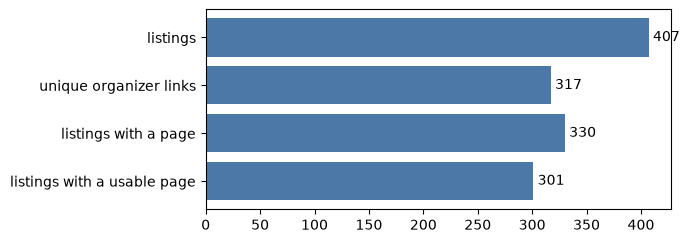

In [44]:
funnel = pd.Series({
    "listings": len(df),
    "unique organizer links": df["key"].nunique(),
    "listings with a page": int(df["has_page"].sum()),
    "listings with a usable page": int(df["page_usable"].sum()),
})
print(funnel.to_string())
print("\npages matching no listing:", int((~pages["key"].isin(listings["key"])).sum()))
print("page problems:", pages["problem"].value_counts(dropna=False).to_dict())
print("unique links still without a page:", df.loc[~df["has_page"], "key"].nunique())

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(funnel.index[::-1], funnel.values[::-1], color="#4c78a8")
for i, v in enumerate(funnel.values[::-1]): ax.text(v + 4, i, str(v), va="center")


So:

- "Listings with a page" (330) means a listing's organizer link was fetched and some text was saved for it. The notebook calculates it as has_page = page_text.notna(). It only checks that text exists, and it can be useless text.

- "Listings with a usable page" (301) is a stricter subset: the page also passes page_problem in clean.py. The notebook computes it as page_usable = has_page & problem.isna(). To recall: a page counts as unusable if it has any of these problems:

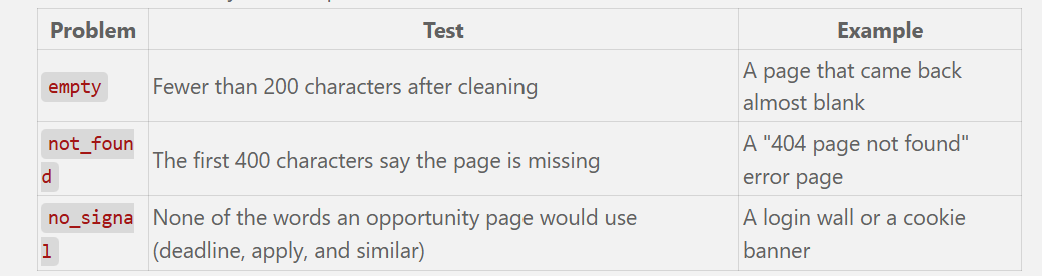

- As noticed above, 25 of the 251 fetched pages are not usable. (14 are "page not found", 7 have no listing words, and 4 are nearly empty.) But the gap is 29 listings and not 25: one page can serve several listings, so 25 bad pages remove 29 listings.

### EDA

We will check for:

1. Completeness (did it earlier too)
2. Label Balance
3. Text Length
4. Time
5. Duplicates
6. source of Noise
7. Analyze the content

title           0.0
description     0.2
deadline        1.7
fees           76.9
website         0.0
type            0.0


Text(0.5, 1.0, 'Field coverage by month')

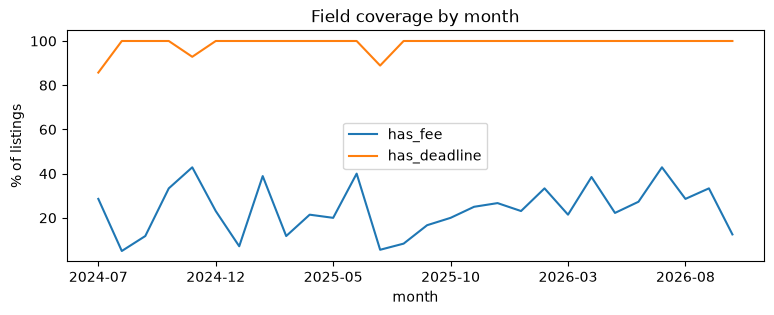

In [ ]:
## Checking for missingness/Completeness of the data

cols = ["title", "description", "deadline", "fees", "website", "type"]
blank = df[cols].replace(r"^\s*$", np.nan, regex=True).isna().mean().mul(100).round(1) # explanation below
print(blank.to_string())

by_month = (df.assign(has_fee=df["fees"].notna(), has_deadline=df["deadline"].notna())
              .groupby("month")[["has_fee", "has_deadline"]].mean().mul(100))
# .assign(...) adds new columns to a copy of the table, without changing df
# here has_fee and has_deadline  are new columns
# the groupby operation then calculates the mean of these boolean columns for each month, then converted into %

fig, ax = plt.subplots(figsize=(9, 3))
by_month.plot(ax=ax); ax.set_ylabel("% of listings"); ax.set_title("Field coverage by month")

For finding the missing values in each column, we are first replacing any empty string or string with only whitespace with NaN (^ is the start of the text, \s* is any number of whitespace characters, including none, $ is the end of the text), then checking which columns have NaN values, calculating the mean (which gives us the proportion of NaN values), multiplying by 100 to get a percentage, and rounding to 1 decimal place. This gives us the 'percentage of listings' that have blank values for each of the specified columns.

- Fees has highest missing values - this might be a problem while training.
- Then Deadlines have second highest missing values, even though there are only 1.7%


type
Residency/Fellowship    181
Grant                   125
Open Call               101


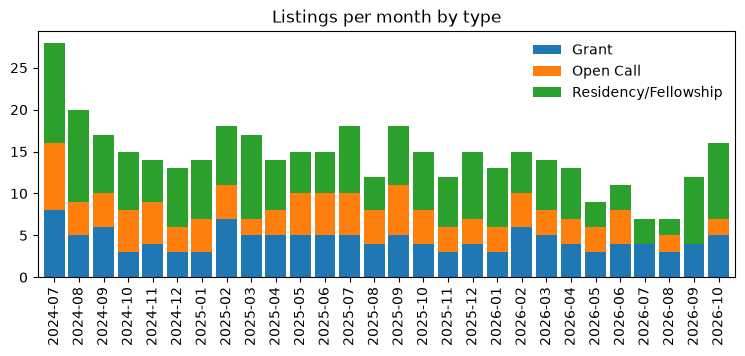

In [56]:
## Next, we will check the distribution of the type of listings, and the distribution of the number of listings per organizer (domain)

print(df["type"].value_counts().to_string())
ct = pd.crosstab(df["month"], df["type"])
# print(ct)
fig, ax = plt.subplots(figsize=(9, 3.2))
ct.plot.bar(stacked=True, ax=ax, width=0.85); ax.set_title("Listings per month by type"); ax.set_xlabel("")
ax.legend(frameon=False); # to remove the box around the legend
# save(fig, "type_by_month"); 
plt.show()

In [ ]:
# checking ratio of residency/fellowship vs. rest for each month


In [ ]:
# listings per organizer (domain)
org_counts = df.groupby("domain").size()
org_counts.sort_values(ascending=False).head(10)

domain
jonathanandbarbarasilverfoundation.org    8
centerforcraft.org                        7
apexart.org                               7
foundwork.art                             6
arts.princeton.edu                        5
lbifoundation.org                         5
vilcek.org                                5
thebennettprize.org                       5
vermontstudiocenter.org                   5
morganconservatory.org                    4
dtype: int64

- Residency/Fellowship are highest type of opporunities
- 